In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


# Lib


In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import os
import copy
import random
from pathlib import Path
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision.models import (
    resnet34,
    resnet50,
    ResNet34_Weights,
    ResNet50_Weights,
)

from scipy.ndimage import binary_erosion, distance_transform_edt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# Set Seed


In [ ]:
SEED = 42


def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


set_seed(SEED)
print(f"Global seed: {SEED}")

Global seed: 42


# Data Augmentation


In [ ]:
def build_train_transform(height=256, width=256):
    return A.Compose(
        [
            A.Resize(height=height, width=width),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.RandomRotate90(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.05,
                scale_limit=0.10,
                rotate_limit=15,
                border_mode=cv2.BORDER_CONSTANT,
                p=0.4,
            ),
            A.RandomBrightnessContrast(p=0.3),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
            ToTensorV2(),
        ]
    )


def build_eval_transform(height=256, width=256):
    return A.Compose(
        [
            A.Resize(height=height, width=width),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
            ToTensorV2(),
        ]
    )

# Data Preparation


In [ ]:
CLASS_NAMES = {
    0: "background",
    1: "non-neoplastic",
    2: "neoplastic",
}

CLASS_COLORS = {
    0: (0, 0, 0),
    1: (0, 255, 0),
    2: (255, 0, 0),
}


def decode_ground_truth(mask_rgb):
    """
    To RGB mask -> class-index mask 0/1/2.

    Class mapping:
        0 = background      -> black
        1 = non-neoplastic  -> green
        2 = neoplastic      -> red

    Using nearest-color matching to handle or correct any color variations in the mask image.
    This function will convert an RGB mask into a 2D array where each pixel's value corresponds to its class ID (0, 1, or 2).
    """
    mask = np.asarray(mask_rgb)

    # If the mask is already a 2D array (grayscale), we assume it contains class IDs directly.
    if mask.ndim == 2:
        unique_values = np.unique(mask)

        if np.isin(unique_values, [0, 1, 2]).all():
            return mask.astype(np.uint8)

        raise ValueError(
            "Grayscale mask must contain only class IDs 0, 1, 2. "
            f"Found: {unique_values[:20]}"
        )

    if mask.ndim != 3 or mask.shape[-1] != 3:
        raise ValueError(f"Expected HxWx3 RGB mask, got shape={mask.shape}")

    colors = np.array(
        [
            [0, 0, 0],  # background
            [0, 255, 0],  # non-neoplastic
            [255, 0, 0],  # neoplastic
        ],
        dtype=np.float32,
    )

    pixels = mask.astype(np.float32)

    # Shape:
    # pixels -> [H, W, 1, 3]
    # colors -> [1, 1, 3, 3]
    # result -> [H, W, 3]
    diff = pixels[:, :, None, :] - colors[None, None, :, :]

    distances = np.sum(
        diff**2,
        axis=-1,
    )

    class_mask = np.argmin(
        distances,
        axis=-1,
    )

    return class_mask.astype(np.uint8)


def class_mask_to_rgb(class_mask):
    """
    Convert class-index mask 0/1/2 -> RGB.
    """
    class_mask = np.asarray(class_mask)

    rgb = np.zeros(
        (*class_mask.shape, 3),
        dtype=np.uint8,
    )

    for class_id, color in CLASS_COLORS.items():
        rgb[class_mask == class_id] = color

    return rgb


def _pick_column(
    df,
    explicit_column=None,
    candidates=None,
    required=True,
):
    if explicit_column is not None:
        if explicit_column not in df.columns:
            raise KeyError(
                f"Column '{explicit_column}' not found. "
                f"Available: {df.columns.tolist()}"
            )

        return explicit_column

    candidates = candidates or []

    normalized = {str(col).strip().lower(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in normalized:
            return normalized[candidate.lower()]

    if len(df.columns) == 1:
        return df.columns[0]

    if required:
        raise KeyError(
            "Cannot infer CSV column automatically. "
            f"Available columns: {df.columns.tolist()}"
        )

    return None


class PolypSegmentationDataset(Dataset):
    IMAGE_COLUMN_CANDIDATES = [
        "image",
        "image_name",
        "image_path",
        "filename",
        "file_name",
        "file",
        "id",
    ]

    MASK_COLUMN_CANDIDATES = [
        "mask",
        "mask_name",
        "mask_path",
        "label",
        "label_path",
        "gt",
        "gt_path",
    ]

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir=None,
        transform=None,
        image_col=None,
        mask_col=None,
        has_mask=True,
    ):
        self.df = dataframe.reset_index(drop=True).copy()

        self.image_dir = Path(image_dir)

        self.mask_dir = Path(mask_dir) if mask_dir is not None else None

        self.transform = transform
        self.has_mask = has_mask

        self.image_col = _pick_column(
            self.df,
            explicit_column=image_col,
            candidates=self.IMAGE_COLUMN_CANDIDATES,
            required=True,
        )

        if self.has_mask:
            if self.mask_dir is None:
                raise ValueError("mask_dir is required when has_mask=True.")

            self.mask_col = _pick_column(
                self.df,
                explicit_column=mask_col,
                candidates=self.MASK_COLUMN_CANDIDATES,
                required=False,
            )

        else:
            self.mask_col = None

    @staticmethod
    def _resolve_path(root_dir, value):
        candidate = Path(str(value))

        if candidate.is_absolute():
            return candidate

        return Path(root_dir) / str(value)

    def __len__(self):
        return len(self.df)

    def get_image_path(self, index):
        value = self.df.iloc[index][self.image_col]

        return self._resolve_path(
            self.image_dir,
            value,
        )

    def get_mask_path(self, index):
        if not self.has_mask:
            return None

        row = self.df.iloc[index]

        if self.mask_col is not None:
            mask_value = row[self.mask_col]
        else:
            mask_value = row[self.image_col]

        return self._resolve_path(
            self.mask_dir,
            mask_value,
        )

    def __getitem__(self, index):
        image_path = self.get_image_path(index)

        image_bgr = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR,
        )

        if image_bgr is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        if not self.has_mask:
            if self.transform is not None:
                transformed = self.transform(image=image)

                image = transformed["image"]

            return {
                "image": image,
                "image_path": str(image_path),
                "image_name": image_path.name,
            }

        mask_path = self.get_mask_path(index)

        mask_raw = cv2.imread(
            str(mask_path),
            cv2.IMREAD_UNCHANGED,
        )

        if mask_raw is None:
            raise FileNotFoundError(f"Cannot read mask: {mask_path}")

        if mask_raw.ndim == 3:
            mask_raw = cv2.cvtColor(
                mask_raw,
                cv2.COLOR_BGR2RGB,
            )

        # Nearest-color RGB -> class ID.
        mask = decode_ground_truth(mask_raw)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                mask=mask,
            )

            image = transformed["image"]
            mask = transformed["mask"]

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)

        return {
            "image": image,
            "mask": mask.long(),
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "image_name": image_path.name,
        }

# Architecture


## Unet


In [ ]:
class ResNetEncoder(nn.Module):
    """
    ResNet encoder backbone.

    Supports:
        resnet18, resnet34, resnet50, resnet101

    Returns:
        [x0, x1, x2, x3, x4]
    """

    def __init__(
        self,
        backbone="resnet34",
        pretrained=True,
    ):
        super().__init__()

        backbone = backbone.lower()

        if backbone == "resnet18":
            weights = ResNet18_Weights.DEFAULT if pretrained else None
            model = resnet18(weights=weights)
            self.out_channels = [64, 64, 128, 256, 512]

        elif backbone == "resnet34":
            weights = ResNet34_Weights.DEFAULT if pretrained else None
            model = resnet34(weights=weights)
            self.out_channels = [64, 64, 128, 256, 512]

        elif backbone == "resnet50":
            weights = ResNet50_Weights.DEFAULT if pretrained else None
            model = resnet50(weights=weights)
            self.out_channels = [64, 256, 512, 1024, 2048]

        elif backbone == "resnet101":
            weights = ResNet101_Weights.DEFAULT if pretrained else None
            model = resnet101(weights=weights)
            self.out_channels = [64, 256, 512, 1024, 2048]

        else:
            raise ValueError(
                f"Unsupported backbone: {backbone}. "
                "Supported: resnet18, resnet34, "
                "resnet50, resnet101"
            )

        self.conv1 = model.conv1
        self.bn1 = model.bn1
        self.relu = model.relu
        self.maxpool = model.maxpool

        self.layer1 = model.layer1
        self.layer2 = model.layer2
        self.layer3 = model.layer3
        self.layer4 = model.layer4

    def forward(self, x):
        x0 = self.relu(self.bn1(self.conv1(x)))  # H/2

        x = self.maxpool(x0)  # H/4
        x1 = self.layer1(x)  # H/4
        x2 = self.layer2(x1)  # H/8
        x3 = self.layer3(x2)  # H/16
        x4 = self.layer4(x3)  # H/32

        return [x0, x1, x2, x3, x4]

    def freeze(self):
        for parameter in self.parameters():
            parameter.requires_grad = False

    def unfreeze(self):
        for parameter in self.parameters():
            parameter.requires_grad = True

In [ ]:
class DoubleConv(nn.Module):
    """
    (Conv2d -> BatchNorm -> ReLU) * 2
    """

    def __init__(
        self,
        in_channels,
        out_channels,
    ):
        super().__init__()

        self.double_conv = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class Up(nn.Module):
    """
    Upsample decoder feature, concat encoder skip,
    sau đó DoubleConv.
    """

    def __init__(
        self,
        decoder_channels,
        skip_channels,
        out_channels,
        bilinear=False,
    ):
        super().__init__()

        if bilinear:
            self.up = nn.Sequential(
                nn.Upsample(
                    scale_factor=2,
                    mode="bilinear",
                    align_corners=True,
                ),
                nn.Conv2d(
                    decoder_channels,
                    out_channels,
                    kernel_size=1,
                ),
            )
        else:
            self.up = nn.ConvTranspose2d(
                decoder_channels,
                out_channels,
                kernel_size=2,
                stride=2,
            )

        self.conv = DoubleConv(
            out_channels + skip_channels,
            out_channels,
        )

    def forward(self, x, skip):
        x = self.up(x)

        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)

        if diff_x != 0 or diff_y != 0:
            x = F.pad(
                x,
                [
                    diff_x // 2,
                    diff_x - diff_x // 2,
                    diff_y // 2,
                    diff_y - diff_y // 2,
                ],
            )

        x = torch.cat([skip, x], dim=1)

        return self.conv(x)


class OutConv(nn.Module):
    def __init__(
        self,
        in_channels,
        n_classes,
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            n_classes,
            kernel_size=1,
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    """
    U-Net with ResNet encoder backbone.

    Output:
        logits: (B, n_classes, H, W)

    return_features=True:
        return encoder/bottleneck/decoder features.
    """

    def __init__(
        self,
        backbone="resnet34",
        n_classes=3,
        pretrained=True,
        bilinear=False,
    ):
        super().__init__()

        self.backbone_name = backbone
        self.n_classes = n_classes
        self.pretrained = pretrained
        self.bilinear = bilinear

        self.encoder = ResNetEncoder(
            backbone=backbone,
            pretrained=pretrained,
        )

        c0, c1, c2, c3, c4 = self.encoder.out_channels

        self.up4 = Up(
            decoder_channels=c4,
            skip_channels=c3,
            out_channels=256,
            bilinear=bilinear,
        )

        self.up3 = Up(
            decoder_channels=256,
            skip_channels=c2,
            out_channels=128,
            bilinear=bilinear,
        )

        self.up2 = Up(
            decoder_channels=128,
            skip_channels=c1,
            out_channels=64,
            bilinear=bilinear,
        )

        self.up1 = Up(
            decoder_channels=64,
            skip_channels=c0,
            out_channels=64,
            bilinear=bilinear,
        )

        if bilinear:
            self.final_up = nn.Sequential(
                nn.Upsample(
                    scale_factor=2,
                    mode="bilinear",
                    align_corners=True,
                ),
                nn.Conv2d(
                    64,
                    32,
                    kernel_size=1,
                ),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
            )
        else:
            self.final_up = nn.Sequential(
                nn.ConvTranspose2d(
                    64,
                    32,
                    kernel_size=2,
                    stride=2,
                ),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
            )

        self.outc = OutConv(
            32,
            n_classes,
        )

    def forward(
        self,
        x,
        return_features=False,
    ):
        input_size = x.shape[-2:]

        features = self.encoder(x)
        x0, x1, x2, x3, x4 = features

        x = self.up4(x4, x3)
        x = self.up3(x, x2)
        x = self.up2(x, x1)
        x = self.up1(x, x0)

        decoder_feature = self.final_up(x)

        logits = self.outc(decoder_feature)

        if logits.shape[-2:] != input_size:
            logits = F.interpolate(
                logits,
                size=input_size,
                mode="bilinear",
                align_corners=False,
            )

        if return_features:
            return logits, {
                "encoder_0": x0,
                "encoder_1": x1,
                "encoder_2": x2,
                "encoder_3": x3,
                "bottleneck": x4,
                "decoder": decoder_feature,
            }

        return logits

    def freeze_encoder(self):
        self.encoder.freeze()

    def unfreeze_encoder(self):
        self.encoder.unfreeze()

# Func


## Metrics


In [ ]:
def multiclass_dice_score(
    logits,
    targets,
    num_classes=3,
    include_background=False,
    eps=1e-7,
):
    preds = torch.argmax(logits, dim=1)
    start_class = 0 if include_background else 1
    scores = []

    for class_id in range(start_class, num_classes):
        pred_c = preds == class_id
        target_c = targets == class_id

        intersection = (pred_c & target_c).sum(dim=(1, 2)).float()

        denominator = pred_c.sum(dim=(1, 2)).float() + target_c.sum(dim=(1, 2)).float()

        score = (2.0 * intersection + eps) / (denominator + eps)

        scores.append(score.mean())

    if not scores:
        return torch.tensor(0.0, device=logits.device)

    return torch.stack(scores).mean()


def hd95_binary(pred_mask, true_mask):
    pred = np.asarray(pred_mask).astype(bool)
    true = np.asarray(true_mask).astype(bool)

    if not pred.any() and not true.any():
        return 0.0

    if not pred.any() or not true.any():
        return np.nan

    pred_surface = pred ^ binary_erosion(pred)
    true_surface = true ^ binary_erosion(true)

    if not pred_surface.any():
        pred_surface = pred

    if not true_surface.any():
        true_surface = true

    dist_to_true = distance_transform_edt(~true_surface)
    dist_to_pred = distance_transform_edt(~pred_surface)

    d1 = dist_to_true[pred_surface]
    d2 = dist_to_pred[true_surface]
    distances = np.concatenate([d1, d2])

    return float(np.percentile(distances, 95))


def _safe_divide(numerator, denominator):
    if denominator == 0:
        return np.nan
    return float(numerator / denominator)

## Builders


In [ ]:
def build_criterion(config, device):
    criterion_name = config.get(
        "criterion",
        "cross_entropy",
    ).lower()

    if criterion_name != "cross_entropy":
        raise ValueError(f"Unsupported criterion='{criterion_name}'.")

    class_weights = config.get("class_weights")

    if class_weights is not None:
        class_weights = torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=device,
        )

    return nn.CrossEntropyLoss(weight=class_weights)


def build_optimizer(model, config):
    name = config.get("optimizer", "adamw").lower()
    lr = config.get("learning_rate", 1e-3)
    weight_decay = config.get("weight_decay", 1e-4)

    if name == "adam":
        return torch.optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

    if name == "adamw":
        return torch.optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )

    if name == "sgd":
        return torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=config.get("momentum", 0.9),
            weight_decay=weight_decay,
        )

    raise ValueError(f"Unsupported optimizer='{name}'")


def build_scheduler(optimizer, config):
    name = config.get(
        "scheduler",
        "reduce_on_plateau",
    )

    if name is None:
        return None

    name = str(name).lower()

    if name == "reduce_on_plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=config.get("scheduler_factor", 0.5),
            patience=config.get("scheduler_patience", 3),
            min_lr=config.get("scheduler_min_lr", 1e-7),
        )

    if name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=config.get(
                "scheduler_t_max",
                config.get("epochs", 50),
            ),
            eta_min=config.get("scheduler_min_lr", 1e-7),
        )

    if name == "step":
        return torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=config.get("scheduler_step_size", 10),
            gamma=config.get("scheduler_gamma", 0.5),
        )

    raise ValueError(f"Unsupported scheduler='{name}'")

## Training Utils


In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    num_classes=3,
):
    model.train()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        with torch.no_grad():
            dice = multiclass_dice_score(
                logits,
                masks,
                num_classes=num_classes,
                include_background=False,
            )

        running_loss += loss.item() * batch_size
        running_dice += dice.item() * batch_size
        total_samples += batch_size

    return (
        running_loss / max(total_samples, 1),
        running_dice / max(total_samples, 1),
    )


@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device,
    num_classes=3,
):
    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        logits = model(images)
        loss = criterion(logits, masks)

        batch_size = images.size(0)

        dice = multiclass_dice_score(
            logits,
            masks,
            num_classes=num_classes,
            include_background=False,
        )

        running_loss += loss.item() * batch_size
        running_dice += dice.item() * batch_size
        total_samples += batch_size

    return (
        running_loss / max(total_samples, 1),
        running_dice / max(total_samples, 1),
    )

## Checkpoint Utils


In [ ]:
def clone_state_dict_to_cpu(model):
    return {
        key: value.detach().cpu().clone() for key, value in model.state_dict().items()
    }


def empty_history():
    return {
        "train_loss": [],
        "val_loss": [],
        "train_dice": [],
        "val_dice": [],
    }


def save_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    best_loss,
    best_epoch,
    best_model_state_dict,
    history,
    config,
    checkpoint_dir,
    timestamp_format="%y%m%d_%H%M%S",
):
    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    model_name = model.__class__.__name__
    timestamp = datetime.now().strftime(timestamp_format)

    checkpoint_name = f"{model_name}_epoch_{epoch:02d}_" f"{timestamp}.pth"
    checkpoint_path = checkpoint_dir / checkpoint_name

    payload = {
        "epoch": epoch,
        "model_name": model_name,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": (
            scheduler.state_dict() if scheduler is not None else None
        ),
        "best_loss": best_loss,
        "best_epoch": best_epoch,
        "best_model_state_dict": best_model_state_dict,
        "history": history,
        "config": {
            key: value for key, value in config.items() if not str(key).startswith("_")
        },
    }

    torch.save(payload, checkpoint_path)
    print(f"[Checkpoint] Saved: {checkpoint_path}")

    return checkpoint_path


def load_training_checkpoint(
    checkpoint_path,
    model,
    optimizer=None,
    scheduler=None,
    device="cpu",
):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    return checkpoint


def save_best_model(
    model,
    best_model_state_dict,
    best_loss,
    best_epoch,
    target_epoch,
    history,
    config,
    model_dir,
):
    model_dir = Path(model_dir)
    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    model_name = model.__class__.__name__
    best_path = model_dir / f"best_{model_name}_{target_epoch}.pth"

    payload = {
        "model_name": model_name,
        "model_state_dict": best_model_state_dict,
        "best_loss": best_loss,
        "best_epoch": best_epoch,
        "target_epoch": target_epoch,
        "history": history,
        "config": {
            key: value for key, value in config.items() if not str(key).startswith("_")
        },
        "class_names": CLASS_NAMES,
        "class_colors": CLASS_COLORS,
    }

    torch.save(payload, best_path)
    print("[Best model] Saved after full training: " f"{best_path}")

    return best_path

## Train


In [ ]:
def train(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    config,
    checkpoint_path=None,
):
    """
    Return:
        model, history

    Resume:
        example: checkpoint epoch 10 + config epochs 50 => train epoch 11 ... 50.

        The checkpoint config is resolved before DataLoader/model/optimizer creation.
        This function only restores training states and continues to config["epochs"].
    """
    device = config["device"]
    target_epoch = int(config["epochs"])
    save_every = int(config.get("save_every", 3))

    history = empty_history()
    start_epoch = 1
    best_loss = float("inf")
    best_epoch = 0
    best_model_state_dict = None

    if checkpoint_path:
        checkpoint_path = Path(checkpoint_path)

        if not checkpoint_path.exists():
            raise FileNotFoundError(
                "Resume checkpoint not found: " f"{checkpoint_path}"
            )

        checkpoint = load_training_checkpoint(
            checkpoint_path=checkpoint_path,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            device=device,
        )

        start_epoch = int(checkpoint["epoch"]) + 1

        history = checkpoint.get(
            "history",
            empty_history(),
        )

        best_loss = float(
            checkpoint.get(
                "best_loss",
                float("inf"),
            )
        )

        best_epoch = int(
            checkpoint.get(
                "best_epoch",
                0,
            )
        )

        best_model_state_dict = checkpoint.get("best_model_state_dict")

        print(f"[Resume] epoch {start_epoch - 1} " f"-> target {target_epoch}")
    else:
        print(f"[Train] epoch 1 to target epoch" f"{target_epoch}")

    if start_epoch > target_epoch:
        print(f"[Warning] No epoch to train: " f"start={start_epoch}, " f"target={target_epoch}")
        return model, history

    if best_model_state_dict is None and np.isfinite(best_loss):
        best_model_state_dict = clone_state_dict_to_cpu(model)

    for epoch in range(
        start_epoch,
        target_epoch + 1,
    ):
        train_loss, train_dice = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            num_classes=config["num_classes"],
        )

        val_loss, val_dice = validate_one_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            num_classes=config["num_classes"],
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_dice"].append(train_dice)
        history["val_dice"].append(val_dice)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_model_state_dict = clone_state_dict_to_cpu(model)

        if scheduler is not None:
            if isinstance(
                scheduler,
                torch.optim.lr_scheduler.ReduceLROnPlateau,
            ):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch:02d}/{target_epoch:02d} | "
            f"train_loss={train_loss:.6f} | "
            f"val_loss={val_loss:.6f} | "
            f"train_dice={train_dice:.4f} | "
            f"val_dice={val_dice:.4f} | "
            f"lr={current_lr:.2e} | "
            f"best_val_loss={best_loss:.6f} |"
            f"@ {best_epoch}"
        )

        if save_every > 0 and epoch % save_every == 0:
            save_checkpoint(
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch,
                best_loss=best_loss,
                best_epoch=best_epoch,
                best_model_state_dict=(best_model_state_dict),
                history=history,
                config=config,
                checkpoint_dir=(config["checkpoint_dir"]),
                timestamp_format=(
                    config.get(
                        "timestamp_format",
                        "%y%m%d_%H%M%S",
                    )
                ),
            )

    # Only save best model after full training, not during training.
    if best_model_state_dict is None:
        best_model_state_dict = clone_state_dict_to_cpu(model)
        best_loss = history["val_loss"][-1]
        best_epoch = target_epoch

    save_best_model(
        model=model,
        best_model_state_dict=(best_model_state_dict),
        best_loss=best_loss,
        best_epoch=best_epoch,
        target_epoch=target_epoch,
        history=history,
        config=config,
        model_dir=config["model_dir"],
    )

    # Model returned is the best model, not the last epoch model.
    model.load_state_dict(best_model_state_dict)
    model.to(device)

    return model, history

## Plot


In [ ]:
def plot_history(history):
    epochs = np.arange(
        1,
        len(history["train_loss"]) + 1,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
    )

    axes[0].plot(
        epochs,
        history["train_loss"],
        label="Train loss",
    )
    axes[0].plot(
        epochs,
        history["val_loss"],
        label="Validation loss",
    )
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        epochs,
        history["train_dice"],
        label="Train Dice",
    )
    axes[1].plot(
        epochs,
        history["val_dice"],
        label="Validation Dice",
    )
    axes[1].set_title("Dice")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## Eval


In [ ]:
@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device,
    num_classes=3,
    class_names=None,
):
    """
    Evaluate model on a dataset and compute metrics per class.

    Args:
        model: model to evaluate
        loader: DataLoader of the evaluation dataset
        device: device used for evaluation
        num_classes: number of segmentation classes
        class_names: dictionary mapping class IDs to class names

    Returns:
        DataFrame containing:
            - metrics for each class
            - macro_foreground_only:
                average of foreground classes only
            - macro_all_classes:
                average of all classes including background
    """

    class_names = class_names or {
        i: f"class_{i}"
        for i in range(num_classes)
    }

    tp = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    fp = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    fn = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    hd95_values = {
        class_id: []
        for class_id in range(num_classes)
    }

    model.eval()

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        logits = model(images)

        preds = torch.argmax(
            logits,
            dim=1,
        )

        preds_np = preds.cpu().numpy()
        masks_np = masks.cpu().numpy()

        for class_id in range(num_classes):
            pred_c = preds_np == class_id
            true_c = masks_np == class_id

            tp[class_id] += np.logical_and(
                pred_c,
                true_c,
            ).sum()

            fp[class_id] += np.logical_and(
                pred_c,
                ~true_c,
            ).sum()

            fn[class_id] += np.logical_and(
                ~pred_c,
                true_c,
            ).sum()

            for sample_idx in range(
                preds_np.shape[0]
            ):
                hd95_values[
                    class_id
                ].append(
                    hd95_binary(
                        pred_c[sample_idx],
                        true_c[sample_idx],
                    )
                )

    rows = []

    for class_id in range(num_classes):
        dice = _safe_divide(
            2.0 * tp[class_id],
            (
                2.0 * tp[class_id]
                + fp[class_id]
                + fn[class_id]
            ),
        )

        iou = _safe_divide(
            tp[class_id],
            (
                tp[class_id]
                + fp[class_id]
                + fn[class_id]
            ),
        )

        precision = _safe_divide(
            tp[class_id],
            (
                tp[class_id]
                + fp[class_id]
            ),
        )

        recall = _safe_divide(
            tp[class_id],
            (
                tp[class_id]
                + fn[class_id]
            ),
        )

        hd_values = np.asarray(
            hd95_values[class_id],
            dtype=np.float64,
        )

        hd95 = (
            float(
                np.nanmean(hd_values)
            )
            if np.isfinite(hd_values).any()
            else np.nan
        )

        rows.append(
            {
                "class_id": class_id,
                "class_name": class_names.get(
                    class_id,
                    f"class_{class_id}",
                ),
                "dice": dice,
                "iou": iou,
                "hd95": hd95,
                "precision": precision,
                "recall": recall,
            }
        )

    result = pd.DataFrame(rows)

    # Macro foreground only
    foreground = result[
        result["class_id"].isin(
            range(1, num_classes)
        )
    ]

    macro_fg_row = {
        "class_id": "macro_fg",
        "class_name": "macro_foreground_only",
        "dice": foreground[
            "dice"
        ].mean(skipna=True),
        "iou": foreground[
            "iou"
        ].mean(skipna=True),
        "hd95": foreground[
            "hd95"
        ].mean(skipna=True),
        "precision": foreground[
            "precision"
        ].mean(skipna=True),
        "recall": foreground[
            "recall"
        ].mean(skipna=True),
    }

    # Macro all classes includes background
    all_classes = result[
        result["class_id"].isin(
            range(num_classes)
        )
    ]

    macro_all_row = {
        "class_id": "macro_all",
        "class_name": "macro_all_classes",
        "dice": all_classes[
            "dice"
        ].mean(skipna=True),
        "iou": all_classes[
            "iou"
        ].mean(skipna=True),
        "hd95": all_classes[
            "hd95"
        ].mean(skipna=True),
        "precision": all_classes[
            "precision"
        ].mean(skipna=True),
        "recall": all_classes[
            "recall"
        ].mean(skipna=True),
    }

    return pd.concat(
        [
            result,
            pd.DataFrame(
                [
                    macro_fg_row,
                    macro_all_row,
                ]
            ),
        ],
        ignore_index=True,
    )

## Load model


In [ ]:
def load_model(
    model,
    model_path,
    device,
):
    """
    Load model weights from a checkpoint file and return the model in inference mode.
    """
    payload = torch.load(
        model_path,
        map_location=device,
        weights_only=False,
    )

    if isinstance(payload, dict) and "model_state_dict" in payload:
        state_dict = payload["model_state_dict"]
        history = payload.get("history")
    else:
        state_dict = payload
        history = None

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()

    return model, history

## Inference


In [ ]:
@torch.no_grad()
def inference_model(
    model,
    image_path,
    transform,
    device,
    restore_original_size=True,
):
    """
    Inference one image and return the predicted class mask.

    Input:
        image_path

    Model output:
        logits: [1, num_classes, H, W]

    Prediction:
        argmax -> class mask [H, W]
    """
    model.eval()

    image_bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR,
    )

    if image_bgr is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )

    original_height, original_width = image_rgb.shape[:2]

    transformed = transform(image=image_rgb)

    image_tensor = transformed["image"].unsqueeze(0).to(device)

    logits = model(image_tensor)

    pred_mask = (
        torch.argmax(
            logits,
            dim=1,
        )[0]
        .cpu()
        .numpy()
        .astype(np.uint8)
    )

    if restore_original_size:
        pred_mask = cv2.resize(
            pred_mask,
            (
                original_width,
                original_height,
            ),
            interpolation=cv2.INTER_NEAREST,
        )

    return pred_mask

## Visualization


In [ ]:
def visualize_inference_samples(
    model,
    dataset,
    transform,
    device,
    n_sample=4,
    alpha=0.40,
):
    """
    Random n_sample from dataset.

    Each sample will be visualized in 4 columns:
        Original | Ground Truth | Prediction | Overlay

    Not support batch inference, only one image at a time.
    """
    if n_sample <= 0:
        raise ValueError("n_sample must be greater than 0.")

    if len(dataset) == 0:
        raise ValueError("Dataset is empty.")

    n_sample = min(
        n_sample,
        len(dataset),
    )

    # Random sample indices from the dataset without replacement.
    sample_indices = np.random.choice(
        len(dataset),
        size=n_sample,
        replace=False,
    )

    fig, axes = plt.subplots(
        n_sample,
        4,
        figsize=(20, 5 * n_sample),
    )

    # If n_sample == 1, axes will be a 1D array, we need to expand it to 2D for consistent indexing.
    if n_sample == 1:
        axes = np.expand_dims(
            axes,
            axis=0,
        )

    for row, index in enumerate(sample_indices):

        # Path
        image_path = dataset.get_image_path(index)

        gt_path = dataset.get_mask_path(index)

        # Inference
        pred_mask = inference_model(
            model=model,
            image_path=image_path,
            transform=transform,
            device=device,
            restore_original_size=True,
        )

        # Original image
        image_bgr = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR,
        )

        if image_bgr is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        image_rgb = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        # Ground Truth
        gt_raw = cv2.imread(
            str(gt_path),
            cv2.IMREAD_UNCHANGED,
        )

        if gt_raw is None:
            raise FileNotFoundError(f"Cannot read ground truth: {gt_path}")

        if gt_raw.ndim == 3:
            gt_raw = cv2.cvtColor(
                gt_raw,
                cv2.COLOR_BGR2RGB,
            )

        gt_class = decode_ground_truth(gt_raw)

        gt_rgb = class_mask_to_rgb(gt_class)

        # Prediction RGB
        pred_rgb = class_mask_to_rgb(pred_mask)

        # Resize GT nếu cần
        if gt_rgb.shape[:2] != image_rgb.shape[:2]:
            gt_rgb = cv2.resize(
                gt_rgb,
                (
                    image_rgb.shape[1],
                    image_rgb.shape[0],
                ),
                interpolation=cv2.INTER_NEAREST,
            )

        # Prediction cũng bảo đảm cùng kích thước.
        if pred_rgb.shape[:2] != image_rgb.shape[:2]:
            pred_rgb = cv2.resize(
                pred_rgb,
                (
                    image_rgb.shape[1],
                    image_rgb.shape[0],
                ),
                interpolation=cv2.INTER_NEAREST,
            )

        # Overlay
        overlay = cv2.addWeighted(
            image_rgb,
            1.0 - alpha,
            pred_rgb,
            alpha,
            0,
        )

        # Plot
        axes[row, 0].imshow(image_rgb)
        axes[row, 0].set_title(f"Original\n{image_path.name}")

        axes[row, 1].imshow(gt_rgb)
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(pred_rgb)
        axes[row, 2].set_title("Prediction")

        axes[row, 3].imshow(overlay)
        axes[row, 3].set_title("Overlay")

        for col in range(4):
            axes[row, col].axis("off")

    plt.tight_layout(pad=0.5)
    plt.show()

In [ ]:
def visualize_inference_path(
    model,
    image_path,
    transform,
    device,
    ground_truth_path=None,
    alpha=0.40,
):
    """
    Inference and visualize one image.

    If ground truth is provided:
        Original | Ground Truth | Prediction | Overlay

    If no ground truth is provided:
        Original | Prediction | Overlay
    """
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    pred_mask = inference_model(
        model=model,
        image_path=image_path,
        transform=transform,
        device=device,
        restore_original_size=True,
    )

    image_bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR,
    )

    if image_bgr is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )

    pred_rgb = class_mask_to_rgb(pred_mask)

    if pred_rgb.shape[:2] != image_rgb.shape[:2]:
        pred_rgb = cv2.resize(
            pred_rgb,
            (
                image_rgb.shape[1],
                image_rgb.shape[0],
            ),
            interpolation=cv2.INTER_NEAREST,
        )

    overlay = cv2.addWeighted(
        image_rgb,
        1.0 - alpha,
        pred_rgb,
        alpha,
        0,
    )

    if ground_truth_path is None:
        _, axes = plt.subplots(
            1,
            3,
            figsize=(16, 5),
        )

        panels = [
            (image_rgb, "Original"),
            (pred_rgb, "Prediction"),
            (overlay, "Overlay"),
        ]

    else:
        ground_truth_path = Path(ground_truth_path)

        if not ground_truth_path.exists():
            raise FileNotFoundError(f"Ground truth not found: {ground_truth_path}")

        gt_raw = cv2.imread(
            str(ground_truth_path),
            cv2.IMREAD_UNCHANGED,
        )

        if gt_raw is None:
            raise FileNotFoundError(f"Cannot read ground truth: {ground_truth_path}")

        if gt_raw.ndim == 3:
            gt_raw = cv2.cvtColor(
                gt_raw,
                cv2.COLOR_BGR2RGB,
            )

        gt_class = decode_ground_truth(gt_raw)

        gt_rgb = class_mask_to_rgb(gt_class)

        if gt_rgb.shape[:2] != image_rgb.shape[:2]:
            gt_rgb = cv2.resize(
                gt_rgb,
                (
                    image_rgb.shape[1],
                    image_rgb.shape[0],
                ),
                interpolation=cv2.INTER_NEAREST,
            )

        _, axes = plt.subplots(
            1,
            4,
            figsize=(20, 5),
        )

        panels = [
            (image_rgb, "Original"),
            (gt_rgb, "Ground Truth"),
            (pred_rgb, "Prediction"),
            (overlay, "Overlay"),
        ]

    for ax, (panel, title) in zip(
        axes,
        panels,
    ):
        ax.imshow(panel)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    return pred_mask

# Main


## Config


### Default


In [ ]:
DEFAULT_CONFIG = {
    "seed": SEED,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    # Input image
    "image_height": 256,
    "image_width": 256,
    "num_classes": 3,
    # U-Net
    "backbone": "resnet34",
    "pretrained": True,
    "bilinear": False,
    "freeze_encoder": False,
    # DataLoader
    "batch_size": 16,
    "num_workers": 2,
    # Training
    "epochs": 20,
    "save_every": 3,
    # Loss
    "criterion": "cross_entropy",
    "class_weights": None,
    # Optimizer
    "optimizer": "adamw",
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "momentum": 0.9,
    # Scheduler
    "scheduler": "reduce_on_plateau",
    "scheduler_factor": 0.2,
    "scheduler_patience": 2,
    "scheduler_min_lr": 1e-7,
    # CSV / mask
    "image_col": None,
    "mask_col": None,
    # Checkpoint naming
    "timestamp_format": "%y%m%d_%H%M%S",
}

### Path


In [ ]:
PROJECT_ROOT = Path("/content/drive/MyDrive/colab")

DATA_DIR = PROJECT_ROOT / "data"
SPLIT_DIR = DATA_DIR / "sample"

TRAIN_CSV_PATH = SPLIT_DIR / "train.csv"
VALID_CSV_PATH = SPLIT_DIR / "valid.csv"
TEST_CSV_PATH = SPLIT_DIR / "test.csv"

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
MODEL_DIR = PROJECT_ROOT / "models"

# None: fresh training. Set a checkpoint path to resume.
# If RESUME_CHECKPOINT is set, the training will resume from that checkpoint.
RESUME_CHECKPOINT = None

### Build config


In [ ]:
# Fresh training: Use DEFAULT_CONFIG directly.
# Resume: Use the saved checkpoint config before creating any training objects.
if RESUME_CHECKPOINT is None:
    CONFIG = copy.deepcopy(DEFAULT_CONFIG)
else:
    resume_path = Path(RESUME_CHECKPOINT)

    if not resume_path.exists():
        raise FileNotFoundError(f"Resume checkpoint not found: {resume_path}")

    checkpoint_metadata = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=False,
    )
    checkpoint_config = checkpoint_metadata.get("config")

    if not isinstance(checkpoint_config, dict):
        raise KeyError("Checkpoint does not contain a valid 'config' dictionary.")

    CONFIG = copy.deepcopy(checkpoint_config)

# The current notebook controls the final target epoch.
# Example: checkpoint epoch 10 + DEFAULT_CONFIG["epochs"] = 20 -> train 11 ... 20.
CONFIG["epochs"] = int(DEFAULT_CONFIG["epochs"])

# Runtime paths always come from the current notebook, never from the checkpoint.
CONFIG["checkpoint_dir"] = str(CHECKPOINT_DIR)
CONFIG["model_dir"] = str(MODEL_DIR)

print("Config source:", "checkpoint" if RESUME_CHECKPOINT else "default")
print("Device:", CONFIG["device"])
print("Backbone:", CONFIG["backbone"])
print("Target epochs:", CONFIG["epochs"])
print("Checkpoint dir:", CONFIG["checkpoint_dir"])
print("Model dir:", CONFIG["model_dir"])

Config source: default
Device: cuda
Backbone: resnet34
Target epochs: 20
Checkpoint dir: /content/drive/MyDrive/colab/checkpoints
Model dir: /content/drive/MyDrive/colab/models


## Load data


In [ ]:
train_df = pd.read_csv(TRAIN_CSV_PATH)
valid_df = pd.read_csv(VALID_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)
print("Train:", train_df.shape)
print("Valid:", valid_df.shape)
print("Test :", test_df.shape)

print(
    "Train columns:",
    train_df.columns.tolist(),
)
print(
    "Valid columns:",
    valid_df.columns.tolist(),
)
print(
    "Test columns:",
    test_df.columns.tolist(),
)

Train: (700, 13)
Valid: (100, 11)
Test : (200, 11)
Train columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels', 'labeled_1_4', 'labeled_1_2']
Valid columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels']
Test columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels']


## DataLoader


In [ ]:
train_transform = build_train_transform(
    height=CONFIG["image_height"],
    width=CONFIG["image_width"],
)

eval_transform = build_eval_transform(
    height=CONFIG["image_height"],
    width=CONFIG["image_width"],
)


train_dataset = PolypSegmentationDataset(
    dataframe=train_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=train_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

valid_dataset = PolypSegmentationDataset(
    dataframe=valid_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=eval_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

test_dataset = PolypSegmentationDataset(
    dataframe=test_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=eval_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)


print("Train samples:", len(train_dataset))
print("Valid samples:", len(valid_dataset))
print("Test samples :", len(test_dataset))

Train samples: 700
Valid samples: 100
Test samples : 200


## Check


In [ ]:
sample = train_dataset[0]

image = sample["image"]
mask = sample["mask"]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask classes:", torch.unique(mask))

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([256, 256])
Mask classes: tensor([0, 2])


In [ ]:
for i in range(5):
    sample = train_dataset[i]

    print(
        i,
        sample["image_name"],
        torch.unique(sample["mask"]).tolist(),
    )

0 0081835cf877e004e8bfb905b78a9139.jpeg [0, 2]
1 00f9b6c911c4aa179344271fa54aa1b2.jpeg [0, 2]
2 00fd197cd955fa095f978455cef3593c.jpeg [0, 1]
3 01c13a3d810b000db55759486b8aa1b8.jpeg [0, 1]
4 01e80947f9c02314fc58bdb26679bff5.jpeg [0, 2]


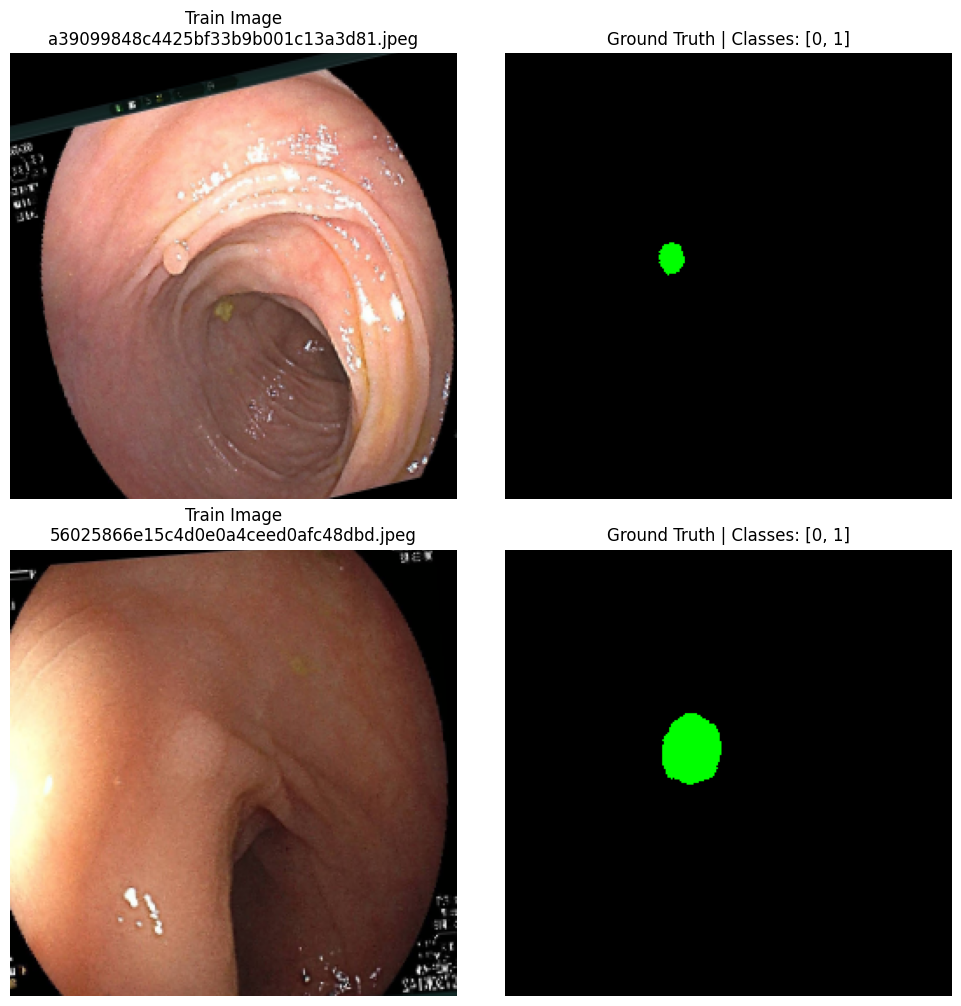

In [ ]:
# Visualize Train Image and Ground Truth
NUM_SAMPLES = 2

indices = np.random.choice(
    len(train_dataset),
    size=min(NUM_SAMPLES, len(train_dataset)),
    replace=False,
)

fig, axes = plt.subplots(
    len(indices),
    2,
    figsize=(10, 5 * len(indices)),
)

if len(indices) == 1:
    axes = np.expand_dims(axes, axis=0)

# ImageNet normalization
mean = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32,
)

std = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32,
)

for row, index in enumerate(indices):
    sample = train_dataset[index]

    image = sample["image"]
    mask = sample["mask"]

    # Tensor [C, H, W] -> numpy [H, W, C]
    image = image.permute(1, 2, 0).cpu().numpy()

    # Denormalize
    image = image * std + mean
    image = np.clip(image, 0, 1)

    mask = mask.cpu().numpy()

    # 0/1/2 -> black/green/red
    mask_rgb = class_mask_to_rgb(mask)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Train Image\n{sample['image_name']}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_rgb)
    axes[row, 1].set_title("Ground Truth " f"| Classes: {np.unique(mask).tolist()}")
    axes[row, 1].axis("off")

plt.tight_layout(pad=0.5)
plt.show()

## Model


In [ ]:
device = torch.device(CONFIG["device"])

model = UNet(
    backbone=CONFIG["backbone"],
    n_classes=CONFIG["num_classes"],
    pretrained=CONFIG["pretrained"],
    bilinear=CONFIG["bilinear"],
).to(device)

if CONFIG.get("freeze_encoder", False):
    model.freeze_encoder()
else:
    model.unfreeze_encoder()

criterion = build_criterion(
    CONFIG,
    device=device,
)

optimizer = build_optimizer(
    model,
    CONFIG,
)

scheduler = build_scheduler(
    optimizer,
    CONFIG,
)

print("Model:", model.__class__.__name__)
print("Backbone:", CONFIG["backbone"])
print("Pretrained:", CONFIG["pretrained"])
print("Bilinear:", CONFIG["bilinear"])
print("Freeze encoder:", CONFIG["freeze_encoder"])

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 199MB/s]


Model: UNet
Backbone: resnet34
Pretrained: True
Bilinear: False
Freeze encoder: False


## Train


In [ ]:
model, history = train(
    model=model,
    train_loader=train_loader,
    val_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    config=CONFIG,
    checkpoint_path=RESUME_CHECKPOINT,
)

[Train] epoch 1 -> target 20
Epoch 01/20 | train_loss=0.541879 | val_loss=0.386677 | train_dice=0.2773 | val_dice=0.3246 | lr=1.00e-03 | best_val_loss=0.386677 |@ 1
Epoch 02/20 | train_loss=0.251627 | val_loss=0.182276 | train_dice=0.4501 | val_dice=0.6050 | lr=1.00e-03 | best_val_loss=0.182276 |@ 2
Epoch 03/20 | train_loss=0.152677 | val_loss=0.136889 | train_dice=0.6320 | val_dice=0.6223 | lr=1.00e-03 | best_val_loss=0.136889 |@ 3
[Checkpoint] Saved: /content/drive/MyDrive/colab/checkpoints/UNet_epoch_03_260819_060111.pth
Epoch 04/20 | train_loss=0.125652 | val_loss=0.120948 | train_dice=0.6349 | val_dice=0.6387 | lr=1.00e-03 | best_val_loss=0.120948 |@ 4
Epoch 05/20 | train_loss=0.101521 | val_loss=0.106006 | train_dice=0.6540 | val_dice=0.6289 | lr=1.00e-03 | best_val_loss=0.106006 |@ 5
Epoch 06/20 | train_loss=0.089217 | val_loss=0.102379 | train_dice=0.6496 | val_dice=0.6762 | lr=1.00e-03 | best_val_loss=0.102379 |@ 6
[Checkpoint] Saved: /content/drive/MyDrive/colab/checkpoints/U

# I/O


## Load model


In [ ]:
BEST_MODEL_PATH = (
    "/content/drive/MyDrive/colab/checkpoints/UNet_epoch_12_260819_045803.pth"
)

In [ ]:
model = UNet(
    backbone=CONFIG["backbone"],
    n_classes=CONFIG["num_classes"],
    pretrained=False,
    bilinear=CONFIG["bilinear"],
)

model, loaded_history = load_model(
    model=model,
    model_path=BEST_MODEL_PATH,
    device=device,
)

print(f"Loaded: {BEST_MODEL_PATH}")

Loaded: /content/drive/MyDrive/colab/checkpoints/UNet_epoch_12_260819_045803.pth


## Plot loss


In [ ]:
history_to_plot = loaded_history if loaded_history is not None else history
plot_history(history_to_plot)

## Eval


In [ ]:
evaluation_df = evaluate_model(
    model=model,
    loader=test_loader,
    device=device,
    num_classes=CONFIG["num_classes"],
    class_names=CLASS_NAMES,
)

display(evaluation_df.round(4))

## Inference


In [ ]:
N_SAMPLE = 2

visualize_inference_samples(
    model=model,
    dataset=test_dataset,
    transform=eval_transform,
    device=device,
    n_sample=N_SAMPLE,
    alpha=0.40,
)

In [ ]:
IMAGE_PATH = DATA_DIR / "train" / "train" / "3297c819c908954bb13d3727c7e5e106.jpeg"

GT_PATH = DATA_DIR / "train_gt" / "train_gt" / "3297c819c908954bb13d3727c7e5e106.jpeg"

pred_mask = visualize_inference_path(
    model=model,
    image_path=IMAGE_PATH,
    ground_truth_path=GT_PATH,
    transform=eval_transform,
    device=device,
    alpha=0.40,
)

In [ ]:
# Visualize one image without ground truth (out domain image)
# pred_mask = visualize_inference_path(
#     model=model,
#     image_path="/content/example.jpeg",
#     transform=eval_transform,
#     device=device,
# )